In [2]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("/home/thinkpad/Documents/BrototypeStudying/paper_three/Module12/data/customer_segmentation.csv")
X = df.select_dtypes("number").drop(columns=["customer_id"])

raw_labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X)
X_scaled = StandardScaler().fit_transform(X)
scaled_labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_scaled)

print("raw:", silhouette_score(X, raw_labels))
print("scaled:", silhouette_score(X_scaled, scaled_labels))

raw: 0.5969926234947349
scaled: 0.514871264804581


In [3]:
df["cluster"] = scaled_labels
df.groupby("cluster").mean(numeric_only=True)

,customer_id,age,annual_income_k,spending_score,visits_per_month,avg_basket_value
cluster,,,,,,
0,251.004000,26.376000,32.465600,52.756000,6.144000,22.546560
1,260.416667,44.675000,94.172500,80.583333,6.091667,117.859333
2,240.376923,52.192308,90.169231,20.807692,1.815385,58.367923


In [4]:
df.groupby("cluster").mean(numeric_only=True).drop(columns="customer_id")

,age,annual_income_k,spending_score,visits_per_month,avg_basket_value
cluster,,,,,
0,26.376000,32.465600,52.756000,6.144000,22.546560
1,44.675000,94.172500,80.583333,6.091667,117.859333
2,52.192308,90.169231,20.807692,1.815385,58.367923


In [5]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(accuracy_score(y_test, y_pred))

0.9649122807017544


In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(precision_score(y_test, y_pred))

0.9594594594594594


In [7]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(recall_score(y_test, y_pred))

0.9861111111111112


In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f1_score(y_test, y_pred))

0.9726027397260274


[[39  3]
 [ 1 71]]


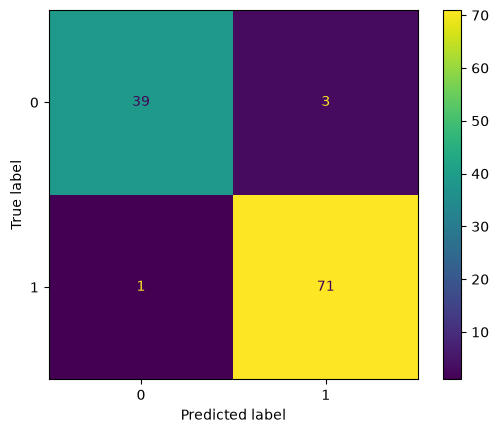

In [11]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print(cm)
ConfusionMatrixDisplay(cm).plot()
plt.show()